# Predicting eruptions at Kilauea from earthquake data — live walkthrough

Run the cells **top to bottom** (Kernel → Restart & Run All, or Shift+Enter one by one).
Everything below is computed live from the two raw CSV files in `data/raw/`: nothing is loaded
from saved results.

**Two tasks, same 7 inputs per earthquake**
- **Task A (classification):** is the volcano erupting when this earthquake happens? (1 / 0)
- **Task B (regression):** how many days until the next eruption starts? (0 if erupting)

Total run time ≈ 2–3 minutes on a laptop (set `RUN_NN = False` below to skip the neural net and
finish in under a minute). Set `DROP_FEATURE` to leave one feature out and see how the results change.

## 0. Setup (Google Colab or your own laptop)

**Colab:** run this cell, click *Choose files* and pick `Part1_Data_Models_Results.zip`.
It unpacks the code and data next to the notebook, and installs scikit-learn 1.9.1 (the version the
saved results were made with, so the numbers match exactly). Colab forgets files when the session
ends, so do this once per session.

**Laptop / Jupyter:** if the notebook is already inside the project folder, this cell does nothing.

In [1]:
import os, sys, glob, zipfile, subprocess
import importlib.metadata as metadata

SKLEARN_VERSION = "1.9.1"   # the version the saved figures and results were made with

try:
    from google.colab import files               # are we in Colab?
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Random forests and k-means come out slightly differently in other scikit-learn versions,
# so install the exact version used for the saved results.
installed = metadata.version("scikit-learn")
if installed != SKLEARN_VERSION:
    if IN_COLAB:
        print(f"Installing scikit-learn {SKLEARN_VERSION} (Colab has {installed}) ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"scikit-learn=={SKLEARN_VERSION}"])
    else:
        print(f"WARNING: scikit-learn {installed} found, results were made with {SKLEARN_VERSION}.")
        print("Run:  pip install -r requirements.txt   then restart the kernel.")

if not os.path.isdir("src") and os.path.isdir("part1/src"):   # already unpacked earlier
    os.chdir("part1")
if not os.path.isdir("src"):                      # code + data not here yet
    if IN_COLAB:
        print("Choose Part1_Data_Models_Results.zip")
        zip_name = next(iter(files.upload()))
    else:                                         # local: look for the zip next to the notebook
        found = glob.glob("Part1*.zip")
        if not found:
            raise FileNotFoundError("Put Part1_Data_Models_Results.zip next to this notebook")
        zip_name = found[0]
    zipfile.ZipFile(zip_name).extractall(".")
    os.chdir("part1")

sys.path.insert(0, os.getcwd())
print("Working folder:", os.getcwd())
print("Found:", sorted(os.listdir(".")))

Working folder: /home/claude/part1
Found: ['.gitignore', 'DEMO_SCRIPT.md', 'HANDOFF.md', 'data', 'demo.py', 'main.py', 'requirements.txt', 'results', 'src', 'tests', 'walkthrough.ipynb']


In [2]:
RUN_NN = True          # neural network adds ~1-2 min; set False for a quick run
DROP_FEATURE = None    # e.g. "eq_rate_30d" or "magnitude" -> Restart & Run All to see the effect

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

from src import config
from src.data import load_earthquakes, load_eruptions, in_east_rift_zone, label_erupting, days_to_next_eruption
from src.features import earthquake_rates
from src.split import make_split
from src.metrics import classification_metrics, regression_metrics
from src.models.logistic import train_logistic
from src.models.kmeans_model import KMeansClassifier, KMeansRegressor, elbow_curve
from src.models.random_forest import tune_random_forest, _make as make_rf
from src.models.neural_net import NNModel

COLORS = {"Logistic Regression": "#2a78d6", "K-means": "#eb6834",
          "Random Forest": "#1baf7a", "Neural Network": "#4a3aa7"}
ERUPT, REPOSE = "#e34948", "#2a78d6"
if DROP_FEATURE:
    config.FEATURES = [f for f in config.FEATURES if f != DROP_FEATURE]
import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
if sklearn.__version__ != SKLEARN_VERSION:
    raise RuntimeError(f"scikit-learn {sklearn.__version__} is loaded, need {SKLEARN_VERSION}. "
                       "Colab: Runtime -> Restart session, then Run all again.")
T0 = time.time()
print("Seed:", config.SEED, "| features used:", config.FEATURES)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3
Seed: 42 | features used: ['longitude', 'latitude', 'depth', 'magnitude', 'eq_rate_1d', 'eq_rate_7d', 'eq_rate_30d']


## 1. Load the raw data

In [3]:
eqs = load_earthquakes()          # data/raw/kilauea_earthquakes_1983_1986.csv
eruptions = load_eruptions()      # data/raw/puuoo_eruption_episodes.csv
print(f"{len(eqs)} earthquakes, {eqs.time.min():%d %b %Y} to {eqs.time.max():%d %b %Y}")
print(f"{len(eruptions)} eruption episodes")
eqs.head()

6485 earthquakes, 01 Jan 1983 to 30 Dec 1986
49 eruption episodes


,time,latitude,longitude,depth,magnitude
0,1983-01-01 00:18:51,19.3052,-155.2292,6.11,1.92
1,1983-01-01 00:43:33,19.3628,-155.1700,3.05,2.14
2,1983-01-01 00:50:44,19.3818,-155.2425,0.98,2.23
3,1983-01-01 01:25:45,19.3442,-155.1575,8.63,2.25
4,1983-01-01 01:58:30,19.3343,-155.0647,6.03,1.78


In [4]:
eruptions.head()

,episode,start,end,length_hours,location
0,1.0,1983-01-03,1983-01-08 03:00:00,99.0,Fissure 1
1,2.0,1983-02-25,1983-03-05 06:00:00,174.0,"Pu'u 'O'o & ""1123"" vent"
2,3.0,1983-03-28,1983-04-10 02:00:00,290.0,Pu'u 'O'o
3,4.0,1983-06-13,1983-06-18 04:00:00,100.0,Pu'u 'O'o
4,5.0,1983-06-29,1983-07-03 18:00:00,90.0,Pu'u 'O'o


## 2. Keep only the East Rift Zone

Keep a quake if it lies on/below the straight line through (lon −155.5, lat 19.3) and
(lon −155.0, lat 19.5). The paper reports **3,764** quakes after this step.

Before: 6485  After: 3764


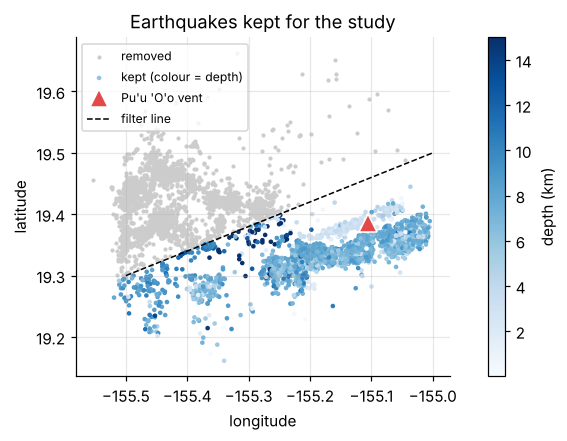

In [5]:
mask = in_east_rift_zone(eqs.latitude.values, eqs.longitude.values)
df = eqs[mask].reset_index(drop=True)
print("Before:", len(eqs), " After:", len(df))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(eqs.longitude[~mask], eqs.latitude[~mask], s=3, c="#cccccc", label="removed")
sc = ax.scatter(df.longitude, df.latitude, s=4, c=df.depth, cmap="Blues", vmax=15, label="kept (colour = depth)")
ax.plot(*config.PUU_OO_LOCATION, "^", color=ERUPT, ms=12, mec="white", label="Pu'u 'O'o vent")
(x1, y1), (x2, y2) = config.RIFT_LINE_POINTS
ax.plot([x1, x2], [y1, y2], "k--", lw=1, label="filter line")
fig.colorbar(sc, label="depth (km)"); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper left")
ax.set(xlabel="longitude", ylabel="latitude", title="Earthquakes kept for the study")
plt.show()

## 3. Create the labels

- `erupting` = 1 if the quake falls inside `[episode start, start + length + 24 h)` of any episode
  (24 h buffer because start dates are only known to the day).
- `days_to_eruption` = days until the next episode starts, 0 if erupting.

erupting
repose (0)      2920
erupting (1)     844
Name: count, dtype: int64
Erupting fraction: 22.4%  -> imbalanced classes


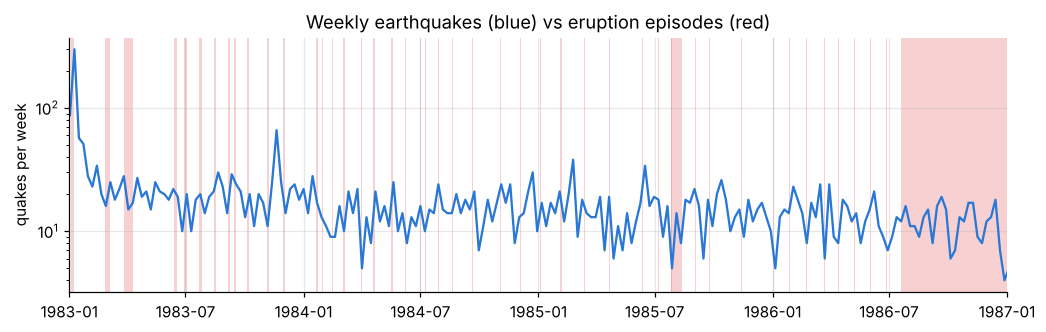

In [6]:
df["erupting"] = label_erupting(df.time, eruptions)
df["days_to_eruption"] = days_to_next_eruption(df.time, eruptions, df.erupting.values)

print(df.erupting.value_counts().rename({0: "repose (0)", 1: "erupting (1)"}))
print(f"Erupting fraction: {df.erupting.mean():.1%}  -> imbalanced classes")

weekly = df.set_index("time").resample("W").size()
fig, ax = plt.subplots(figsize=(11, 3))
for _, e in eruptions.iterrows():
    ax.axvspan(e.start, min(e.end, pd.Timestamp("1987-01-01")), color=ERUPT, alpha=0.25, lw=0)
ax.plot(weekly.index, weekly.values, color=REPOSE)
ax.set(yscale="log", ylabel="quakes per week", title="Weekly earthquakes (blue) vs eruption episodes (red)")
ax.set_xlim(pd.Timestamp("1983-01-01"), pd.Timestamp("1987-01-01"))
plt.show()

## 4. Feature engineering: recent earthquake rates

For each quake, count the **earlier** rift-zone quakes in the previous 1, 7 and 30 days
(only the past: at prediction time we can't see the future).

In [7]:
for name, days in config.RATE_WINDOWS_DAYS.items():
    df[name] = earthquake_rates(df.time, days)
df["month"] = df.time.dt.to_period("M").astype(str)

print("Features:", config.FEATURES)
df[["time"] + config.FEATURES + ["erupting", "days_to_eruption"]].head(8)

Features: ['longitude', 'latitude', 'depth', 'magnitude', 'eq_rate_1d', 'eq_rate_7d', 'eq_rate_30d']


,time,longitude,latitude,depth,magnitude,eq_rate_1d,eq_rate_7d,eq_rate_30d,erupting,days_to_eruption
0,1983-01-01 00:18:51,-155.2292,19.3052,6.11,1.92,0.0,0.0,0.0,0,1.986910
1,1983-01-01 00:43:33,-155.1700,19.3628,3.05,2.14,1.0,1.0,1.0,0,1.969757
2,1983-01-01 00:50:44,-155.2425,19.3818,0.98,2.23,2.0,2.0,2.0,0,1.964769
3,1983-01-01 01:25:45,-155.1575,19.3442,8.63,2.25,3.0,3.0,3.0,0,1.940451
4,1983-01-01 01:58:30,-155.0647,19.3343,6.03,1.78,4.0,4.0,4.0,0,1.917708
5,1983-01-01 05:26:02,-155.1777,19.3493,8.05,1.63,5.0,5.0,5.0,0,1.773588
6,1983-01-01 06:15:16,-155.1820,19.3625,2.73,2.05,6.0,6.0,6.0,0,1.739398
7,1983-01-01 09:37:21,-155.2245,19.3178,7.98,1.65,7.0,7.0,7.0,0,1.599063


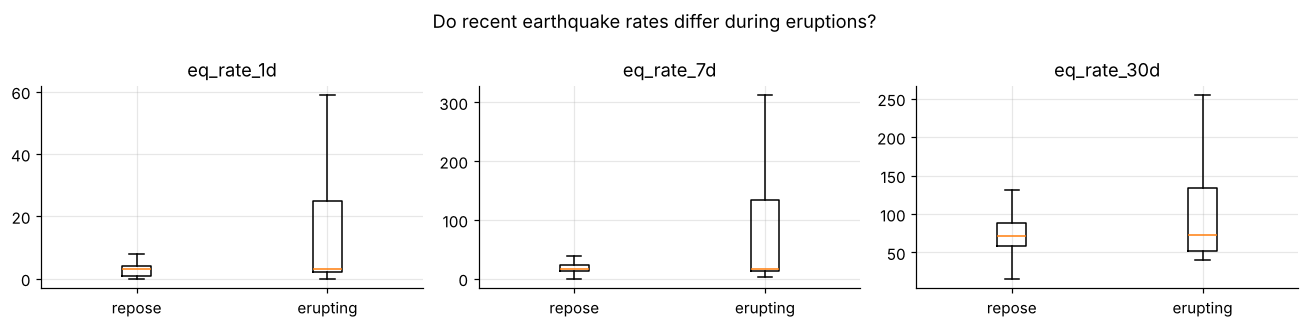

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, f in zip(axes, ["eq_rate_1d", "eq_rate_7d", "eq_rate_30d"]):
    ax.boxplot([df.loc[df.erupting == 0, f], df.loc[df.erupting == 1, f]], showfliers=False)
    ax.set_xticks([1, 2], ["repose", "erupting"]); ax.set_title(f)
fig.suptitle("Do recent earthquake rates differ during eruptions?"); plt.tight_layout(); plt.show()

## 5. Split 70 / 20 / 10 and scale

- **train** fits the models, **dev** chooses hyperparameters, **test** is used once at the end.
- Stratified, so every split keeps ~22 % eruptions.
- The scaler is fit on **train only** (fitting it on everything leaks test information).

In [9]:
sA = make_split(df, "erupting")                              # Task A
sB = make_split(df, "days_to_eruption", scale_target=True)   # Task B (target standardised)
print(f"train {len(sA.y_train)}, dev {len(sA.y_dev)}, test {len(sA.y_test)}")
print(f"erupting share  train {sA.y_train.mean():.3f}  dev {sA.y_dev.mean():.3f}  test {sA.y_test.mean():.3f}")
print(f"1 standardised unit of the regression target = {sB.y_scaler.scale_[0]:.1f} days")

train 2634, dev 753, test 377
erupting share  train 0.224  dev 0.224  test 0.223
1 standardised unit of the regression target = 13.4 days


## 6. Why not accuracy? The naive baseline

A model that always says "not erupting" is ~78 % accurate and useless.
So we use **Cohen's kappa** (0 = chance, 1 = perfect) and **AUROC** (0.5 = random, 1 = perfect).

In [10]:
naive = classification_metrics(sA.y_test, np.zeros_like(sA.y_test), np.zeros(len(sA.y_test)))
print(f"Always 'repose': accuracy {naive['accuracy']:.3f}, kappa {naive['kappa']:.2f}, AUROC {naive['auroc']:.2f}")

Always 'repose': accuracy 0.777, kappa 0.00, AUROC 0.50


# Task A — classification

## 7. Logistic regression (linear baseline)

In [11]:
models_A = {}
models_A["Logistic Regression"] = train_logistic(sA.X_train, sA.y_train)
pd.Series(models_A["Logistic Regression"].coef_[0], index=config.FEATURES, name="weight").round(2).to_frame()

,weight
longitude,-0.07
latitude,0.09
depth,0.07
magnitude,0.01
eq_rate_1d,0.25
eq_rate_7d,1.92
eq_rate_30d,-2.31


## 8. K-means as a classifier

Cluster repose quakes and erupting quakes separately; a new quake gets the label of its nearest
centroid. Choose k with the **elbow method** (where adding clusters stops helping much).

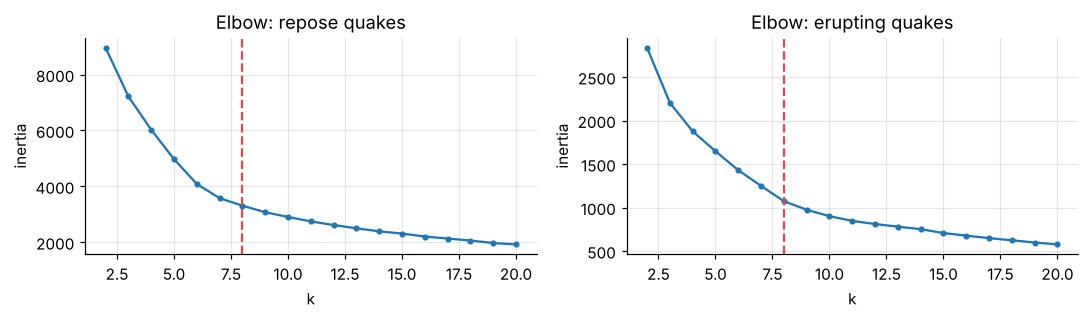

k = 8 clusters per class


In [12]:
ks, inertia0 = elbow_curve(sA.X_train[sA.y_train == 0])
_,  inertia1 = elbow_curve(sA.X_train[sA.y_train == 1])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, inn, t in zip(axes, [inertia0, inertia1], ["repose quakes", "erupting quakes"]):
    ax.plot(ks, inn, "-o", ms=3); ax.axvline(config.KMEANS_K_CLASSIFY, color=ERUPT, ls="--")
    ax.set(title=f"Elbow: {t}", xlabel="k", ylabel="inertia")
plt.tight_layout(); plt.show()

models_A["K-means"] = KMeansClassifier(k=config.KMEANS_K_CLASSIFY).fit(sA.X_train, sA.y_train)
print("k =", config.KMEANS_K_CLASSIFY, "clusters per class")

## 9. Random forest — tune the depth on the dev set

Train AUROC keeps rising (memorising); dev AUROC levels off. Pick the smallest depth on the
dev plateau.

  RF (classification): best max_depth=13, n_estimators=200, dev score=0.827


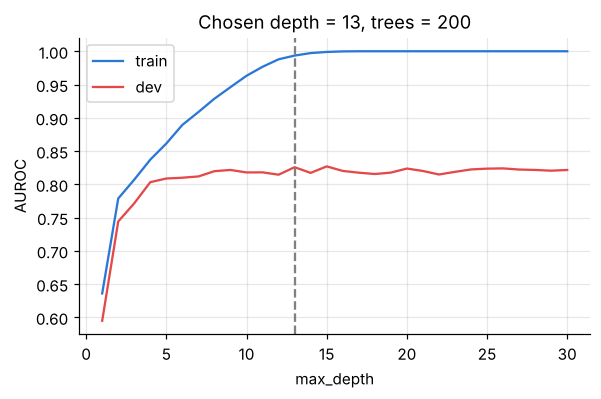

In [13]:
rfA, infoA = tune_random_forest("classification", sA.X_train, sA.y_train, sA.X_dev, sA.y_dev)
models_A["Random Forest"] = rfA
c = infoA["curve"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(c["depth"], c["train"], label="train", color=REPOSE); ax.plot(c["depth"], c["dev"], label="dev", color=ERUPT)
ax.axvline(infoA["best_depth"], color="grey", ls="--"); ax.legend()
ax.set(xlabel="max_depth", ylabel="AUROC", title=f"Chosen depth = {infoA['best_depth']}, trees = {infoA['best_trees']}")
plt.show()

## 10. Neural network (4 hidden layers × 1000 units, PyTorch)

Uses the learning rate / weight decay that won the grid search in `main.py`
(lr 0.01, weight decay 1e-4). Keeps the epoch with the best dev score.

trained in 42s, best dev AUROC 0.764 at epoch 50


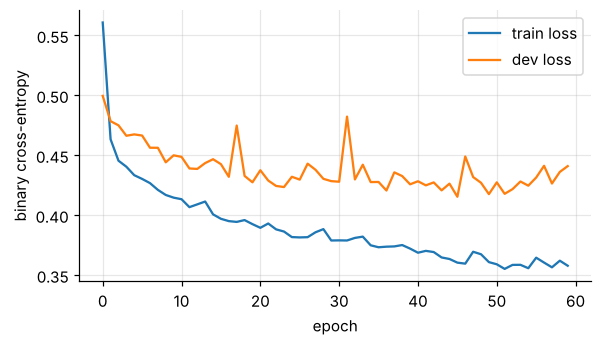

In [14]:
if RUN_NN:
    t = time.time()
    nnA = NNModel("classification", lr=0.01, weight_decay=1e-4).fit(sA.X_train, sA.y_train, sA.X_dev, sA.y_dev)
    models_A["Neural Network"] = nnA
    print(f"trained in {time.time()-t:.0f}s, best dev AUROC {nnA.best_dev:.3f} at epoch {nnA.best_epoch}")
    h = nnA.history
    plt.figure(figsize=(6, 3.2))
    plt.plot(h["train_loss"], label="train loss"); plt.plot(h["dev_loss"], label="dev loss")
    plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.legend(); plt.show()
else:
    print("skipped (RUN_NN = False)")

## 11. Task A results on the test set

In [15]:
def scores(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.predict_score(X)

rows, resA = [], {}
for name, m in models_A.items():
    r = {sp: classification_metrics(y, m.predict(X), scores(m, X))
         for sp, X, y in [("train", sA.X_train, sA.y_train), ("dev", sA.X_dev, sA.y_dev), ("test", sA.X_test, sA.y_test)]}
    resA[name] = r
    rows.append({"model": name, "kappa train": r["train"]["kappa"], "kappa test": r["test"]["kappa"],
                 "AUROC train": r["train"]["auroc"], "AUROC test": r["test"]["auroc"],
                 "recall test": r["test"]["recall"], "precision test": r["test"]["precision"]})
pd.DataFrame(rows).set_index("model").round(2)

,kappa train,kappa test,AUROC train,AUROC test,recall test,precision test
model,,,,,,
Logistic Regression,0.38,0.20,0.74,0.68,0.19,0.59
K-means,0.22,0.13,0.73,0.64,0.55,0.29
Random Forest,0.81,0.37,0.99,0.83,0.32,0.75
Neural Network,0.51,0.26,0.84,0.71,0.24,0.67


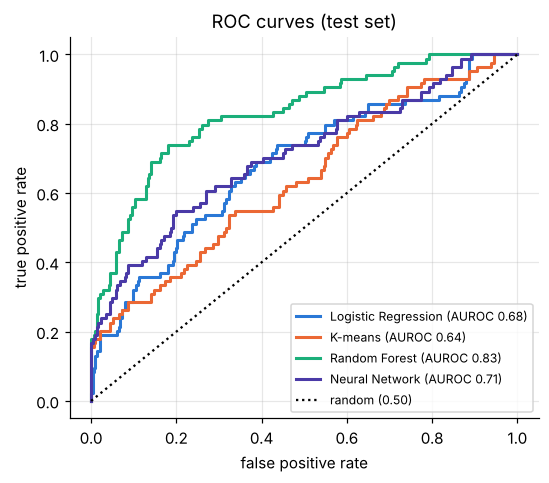

In [16]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, m in models_A.items():
    fpr, tpr, _ = roc_curve(sA.y_test, scores(m, sA.X_test))
    ax.plot(fpr, tpr, color=COLORS[name], lw=2, label=f"{name} (AUROC {resA[name]['test']['auroc']:.2f})")
ax.plot([0, 1], [0, 1], "k:", label="random (0.50)")
ax.set(title="ROC curves (test set)", xlabel="false positive rate", ylabel="true positive rate"); ax.legend(fontsize=8)
plt.show()

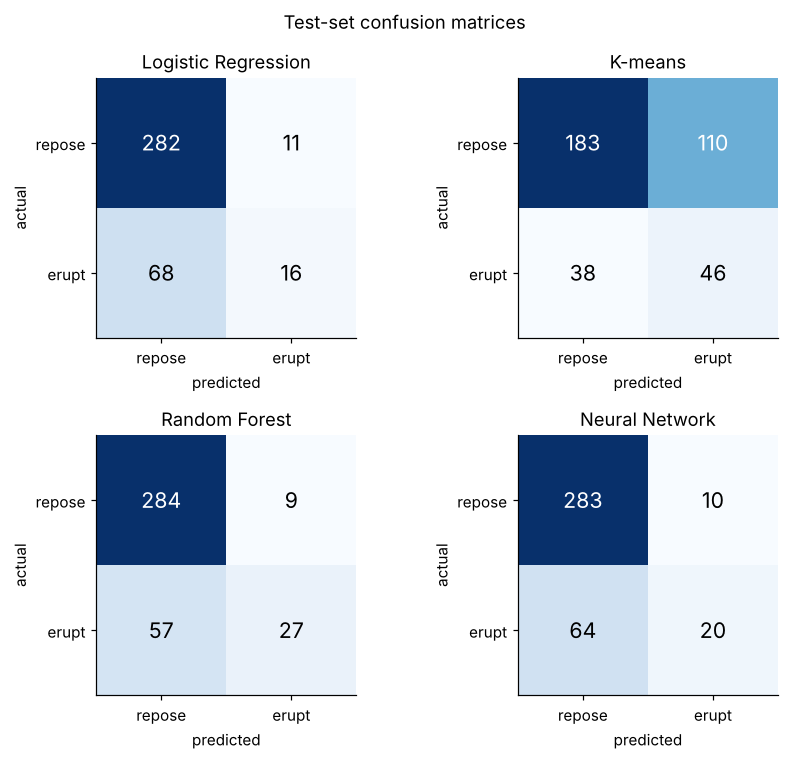

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, (name, r) in zip(axes.ravel(), resA.items()):
    cm = np.array(r["test"]["confusion"]); ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=14)
    ax.set_xticks([0, 1], ["repose", "erupt"]); ax.set_yticks([0, 1], ["repose", "erupt"])
    ax.set(title=name, xlabel="predicted", ylabel="actual")
for ax in axes.ravel()[len(resA):]:
    ax.axis("off")
fig.suptitle("Test-set confusion matrices"); plt.tight_layout(); plt.show()

# Task B — time to eruption (regression)

## 12. Train k-means, random forest, neural network

In [18]:
models_B = {}
models_B["K-means"] = KMeansRegressor(k=config.KMEANS_K_REGRESS).fit(sB.X_train, sB.y_train)
rfB, infoB = tune_random_forest("regression", sB.X_train, sB.y_train, sB.X_dev, sB.y_dev)
models_B["Random Forest"] = rfB
if RUN_NN:
    models_B["Neural Network"] = NNModel("regression", lr=0.01, weight_decay=1e-3).fit(
        sB.X_train, sB.y_train, sB.X_dev, sB.y_dev)

days = sB.y_scaler.scale_[0]
rows = []
for name, m in models_B.items():
    r = {sp: regression_metrics(y, m.predict(X))
         for sp, X, y in [("train", sB.X_train, sB.y_train), ("dev", sB.X_dev, sB.y_dev), ("test", sB.X_test, sB.y_test)]}
    rows.append({"model": name, "R2 train": r["train"]["r2"], "R2 test": r["test"]["r2"],
                 "RMSE test (std)": r["test"]["rmse"], "RMSE test (days)": r["test"]["rmse"] * days})
pd.DataFrame(rows).set_index("model").round(2)

  RF (regression): best max_depth=13, n_estimators=100, dev score=0.395


,R2 train,R2 test,RMSE test (std),RMSE test (days)
model,,,,
K-means,-0.43,-0.70,1.35,18.10
Random Forest,0.69,0.47,0.76,10.11
Neural Network,0.32,0.28,0.88,11.76


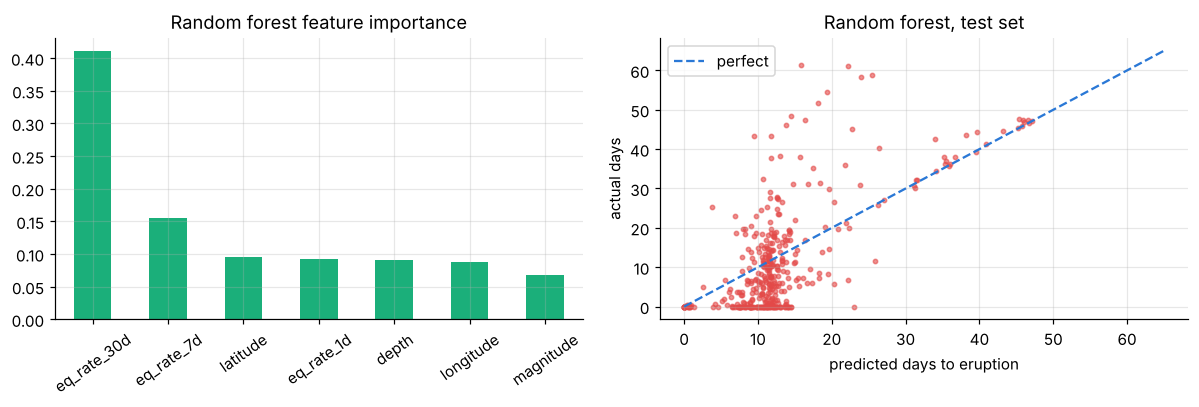

eq_rate_30d    0.41
eq_rate_7d     0.16
latitude       0.10
eq_rate_1d     0.09
depth          0.09
longitude      0.09
magnitude      0.07
dtype: float64


In [19]:
imp = pd.Series(rfB.feature_importances_, index=config.FEATURES).sort_values(ascending=False)
pred = rfB.predict(sB.X_test)
to_days = lambda v: sB.y_scaler.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
imp.plot.bar(ax=axes[0], color=COLORS["Random Forest"]); axes[0].set_title("Random forest feature importance")
axes[0].tick_params(axis="x", rotation=35)
axes[1].scatter(to_days(pred), to_days(sB.y_test), s=8, alpha=0.6, color=ERUPT)
axes[1].plot([0, 65], [0, 65], "--", color=REPOSE, label="perfect")
axes[1].set(xlabel="predicted days to eruption", ylabel="actual days", title="Random forest, test set"); axes[1].legend()
plt.tight_layout(); plt.show()
print(imp.round(2))

# 13. Extra experiment — is the random split honest?

Earthquakes come in **swarms**: quakes minutes apart have almost the same features and the same
label. A random split puts swarm-mates in both train and test, so the model can just recognise the
swarm. Test: 5-fold cross-validation with random folds vs folds where **each calendar month stays
together**.

Random folds:        AUROC 0.83  kappa 0.46
Month-grouped folds: AUROC 0.58  kappa 0.03


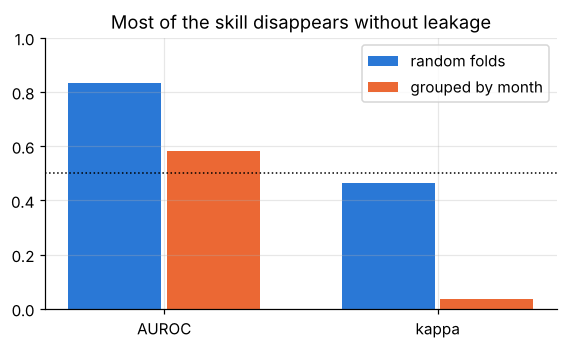

In [20]:
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, cohen_kappa_score

X, y, groups = df[config.FEATURES].values, df.erupting.values, df.month.values

def cv_auc_kappa(splitter, *args):
    auc, kap = [], []
    for tr, te in splitter.split(X, *args):
        sc = StandardScaler().fit(X[tr])
        m = make_rf("classification", infoA["best_depth"], infoA["best_trees"]).fit(sc.transform(X[tr]), y[tr])
        p = m.predict_proba(sc.transform(X[te]))[:, 1]
        auc.append(roc_auc_score(y[te], p)); kap.append(cohen_kappa_score(y[te], p >= 0.5))
    return np.mean(auc), np.mean(kap)

rand = cv_auc_kappa(StratifiedKFold(5, shuffle=True, random_state=config.SEED), y)
grp = cv_auc_kappa(GroupKFold(5), y, groups)
print(f"Random folds:        AUROC {rand[0]:.2f}  kappa {rand[1]:.2f}")
print(f"Month-grouped folds: AUROC {grp[0]:.2f}  kappa {grp[1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
x = np.arange(2)
ax.bar(x - 0.18, rand, 0.34, label="random folds", color=REPOSE)
ax.bar(x + 0.18, grp, 0.34, label="grouped by month", color="#eb6834")
ax.axhline(0.5, color="k", ls=":", lw=1); ax.set_xticks(x, ["AUROC", "kappa"]); ax.legend(); ax.set_ylim(0, 1)
ax.set_title("Most of the skill disappears without leakage"); plt.show()

# 14. Try your own earthquake

Change the numbers and re-run this cell.

In [21]:
quake = {"latitude": 19.33, "longitude": -155.12, "depth": 7.5, "magnitude": 2.1,
         "eq_rate_1d": 60, "eq_rate_7d": 200, "eq_rate_30d": 300}

x = sA.x_scaler.transform(np.array([[quake[f] for f in config.FEATURES]]))
p = rfA.predict_proba(x)[0, 1]
d = to_days(rfB.predict(sB.x_scaler.transform(np.array([[quake[f] for f in config.FEATURES]]))))[0]
print(f"P(erupting) = {p:.2f}  ->  {'ERUPTING' if p >= 0.5 else 'repose'}")
print(f"Predicted days until next eruption: {max(d, 0):.1f}")
print(f"\nWhole notebook ran in {time.time() - T0:.0f} s")

P(erupting) = 0.97  ->  ERUPTING
Predicted days until next eruption: 0.0

Whole notebook ran in 112 s
